# Assignment 4 - Population-based metaheuristics for the Set Covering Problem (SCP)

**Course:** Heuristic Optimization &nbsp;|&nbsp; **Deadline:** 23/10/26 &nbsp;|&nbsp; **Status:** first iteration - *Design* and *Implementation 1 (working version)*; *Parameter tuning and improvement* (part 2) follows later.

**Task.** Choose a family of population-based metaheuristics, **justify** the choice, **design** it for the SCP (representation, feasibility, evaluation, initial population, new solutions,
population update, diversity, stopping), sketch the pseudocode of one run, and implement a **working end-to-end version** that is transparent and verifiable.

**Our choice: a Genetic Algorithm (GA)** built on the blocks of the previous assignments (incremental solution state, greedy repair with the CH3 rule, redundancy elimination RE, drop-and-repair move).

| Step | Content |
|---|---|
| 1 | **Theory** (lecture "An Evolutionary Approach" and the slides on genetic / memetic algorithms and ACO) |
| 2 | **Design:** choice of the family, the eight design questions, pseudocode of one run, why RE |
| 3-4 | Data and the building blocks we re-use (state, repair, RE, move) |
| 5 | **Representation:** one individual = one binary vector; decoding; "show one individual" |
| 6 | **GA operators:** initial population, selection, crossover (with a worked example), mutation, population update |
| 7 | The complete GA |
| 8 | **Working version** on one instance: run, verification of the best solution, randomness and seeds |
| 9 | **The five questions** to be ready for - answered with the running code |
| 10 | Justification of RE and check of the components (ablation) |
| 11 | Preliminary results on several instances |
| 12 | **Quality versus effort:** the GA against all methods of Assignments 1-3 (42 instances, 10 seeds) |
| 13 | Parameters and baseline configuration for the tuning phase (part 2, not executed here) |
| 14 | Conclusions of the first iteration |

Style rules as before: plain functions (no classes), a solution state is a dictionary of arrays, every change of a state is incremental.

## 1. Theory

### 1.1 From one solution to a population
The methods of the previous lectures (constructive heuristics, local search, SA, TS) keep **one current solution** and try to improve it in the next step.
The new idea: maintain **several solutions simultaneously** - a **population** - and let them *compete* for room in the next generation, while **random variation** searches for new solutions as in natural evolution.
This is not a parallel search (several independent runs): the solutions in the population **interact** through selection and recombination.

```
procedure evolutionary algorithm
    t = 0; initialize P(t); evaluate P(t)
    while not termination-condition:
        t = t + 1
        select P(t) from P(t-1)          # competition: better individuals are favoured
        alter P(t)                       # crossover (recombination of 2 or more solutions) and mutation (modification of one)
        evaluate P(t)
```

*Metaphor (Darwin):* the fittest survive longer and reproduce more, so the next generation is fitter in proportion; the less fit have less opportunity to reproduce; accidents (mutation) create new characteristics.
**One solution = one individual (chromosome)**; its quality is its **fitness**; individuals with a good fitness are selected for **recombination (crossover)**; occasionally **mutation** changes an individual.

### 1.2 The ingredients of a genetic algorithm (GA)
General implementation decisions: *how to codify a solution; how to generate the initial population; how to recombine parents (crossover); how to introduce random variation (mutation); how to evaluate; how to generate the next generation.*

```
1: Generate initial population
2: while stopping criterion not reached do
3:     Select fit individuals for reproduction
4:     Produce offspring through recombination and mutation
5:     Replace less fit individuals in the population with offspring
6: end while                                   # one iteration = one generation
```
*Which lines are problem-specific?* Line 1 (constructing solutions) and line 4 (manipulating solutions needs problem knowledge); the rest is generic once a fitness function exists.

* **Representation (chromosome).** Natural choices: a **binary string** (SAT: one bit per variable), a **permutation** (TSP: ordered list of cities). Any string should ideally be a valid solution; if not, operators must be designed (or corrected) to produce valid ones.
* **Initial population.** Size has no rule (usually 1-1000). It must contain **different** individuals: crossing two identical solutions gives an identical offspring, so recombination becomes useless. A *large* population makes each generation slower - time is incompressible, so there are fewer generations.
  Generation: random solutions, stochastic construction heuristics, hints (known good solutions); deterministic construction would need as many different heuristics as individuals.
* **Evaluation.** The function must be able to *rank* individuals (for SAT the number of satisfied clauses is a better guide than the 0/1 value of the formula); evaluating the population is the most time-consuming part. Roulette wheel needs a fitness that is *maximised*: for a cost $z(i)$ to be minimised use $f_i=z_{max}-z(i)+1$ (the "+1" keeps the worst individual selectable).
* **Selection** favours - without excluding the weak (they might hold the key to escaping a local optimum):
  *roulette wheel* (probability $P(i)=f_i/\sum f$), *tournament* (draw $k$ individuals, keep the best; binary tournament $k=2$ is the most popular), *elitist* (the best $\lambda\%$). Selection only changes the *distribution* of the existing solutions - it creates nothing new.
* **Crossover** recombines parts of two parents (1-point, 2-point, ...). Its usefulness depends on the independence of the components - the aim is that components which together give good solutions stay together.
  For permutations (TSP) cutting and splicing produces duplicated and missing cities, so **corrected** operators are needed (**PMX**, **OX**, **CX**, or "copy the first part of parent 1, then append the cities of parent 2 not yet present").
  The same issue appears for the p-median ($p$ facilities): a crossover of two feasible binary vectors can give a vector with the wrong number of ones.
* **Mutation** perturbs one individual (flip a bit; inversion / insertion / exchange for permutations). It creates diversity when recombination has nothing to mix (a homogeneous population would otherwise stay stuck). **Mutation rate**: too high - chaotic behaviour; too low - useless, stuck in local optima; tuning it is a major design issue.
* **Replacement** (who survives): parents and offspring compete, or only the offspring; *generational* (all replaced), *steady-state* (replace only the worst), *elitist* (the best always survive).
* **Termination:** number of generations, generations without improvement, time limit or a combination.

### 1.3 Memetic algorithms and ACO (related families, same lecture)
* **Memetic algorithm (MA)** = population-based method **plus local search / learning**: a GA with a local search (2-opt for the TSP) applied to the offspring - much better than the plain GA, but each generation is slower (fewer generations, smaller population). Our *mutation* (drop one set, repair, RE) is itself a local-search style move.
* **Ant colony optimisation (ACO):** artificial ants *construct* solutions with a construction heuristic biased by **pheromone** $\tau$ on **solution components** (TSP: edges; $P||C_{max}$: job-to-machine assignments; p-median: open warehouses), with probability $\propto \tau^\alpha\eta^\beta$ (roulette wheel);
  after each iteration pheromone evaporates, $\tau\leftarrow(1-\rho)\tau$, and the ants deposit pheromone proportional to the solution quality. BRKGA and PSO are further families named in the assignment.

### 1.4 What the assignment asks us to justify
For the SCP we must be able to say *how a new solution is produced or updated*: representation, crossover and mutation (GA); a decoder from random keys (BRKGA); solution components and pheromone (ACO); position and update rule (PSO). "If you cannot explain how a new solution is produced, the design is not ready."

## 2. Design

### 2.1 Choice of the family and justification
| Family | The question for the SCP | Can we answer it? | Verdict |
|---|---|---|---|
| **GA** | Meaningful representation, crossover, mutation? | **Yes.** A solution is a *set of columns* = a binary vector. The **sets both parents chose** are natural building blocks that a crossover can keep; the repair we already have turns any union of sets into a feasible cover. Mutation = our drop-and-repair move. | **chosen** |
| BRKGA | A useful decoder from random keys to a solution? | Yes (keys $\to$ perturbed costs $\to$ greedy CH3), but the link between the key vector and the cover is indirect: crossover of keys does not "keep sets". | possible, less transparent |
| ACO | Solution components, what should pheromone represent? | Components = columns, pheromone = desirability of a column; construction with CH3 weights. Possible, but ants *construct from scratch* (about the cost of a CH3 per ant) and keep no structure of good solutions except the pheromone. | possible |
| PSO | Meaningful position and update rule? | A binary position with velocity needs a decoder + repair, and the "move towards the best" has no natural meaning for sets. | weakest fit |

**Why GA for the SCP.** (1) The representation is natural and compact (one bit per column) and *every* solution is a set of columns. (2) The SCP solution is a **selection of building blocks (columns)**: a good cover tends to share columns with other good covers, so keeping the columns that two good parents have in common and recombining the rest is a meaningful operator - **path-relinking-like**.
(3) All problem-specific machinery already exists and was validated in Assignments 1-3: the greedy repair (CH3 rule), redundancy elimination and the drop-and-repair move. (4) The assignments so far were single-solution methods; a population with **competition between solutions** is the new ingredient we want to study.

### 2.2 The eight design questions
| # | Question | Our design |
|---|---|---|
| 1 | **Representation** - what is one individual, how does it map to an SCP solution? | A **binary vector** $x\in\{0,1\}^n$ ($n$ = number of columns/sets); $x_j=1$ iff set $j$ is selected. The cover is $\{j: x_j=1\}$, its cost $\sum_j w_jx_j$. The vector is decoded in one step into the incrementally updated state of Assignments 1-3 (`state_from_vector`). |
| 2 | **Feasibility** - can infeasibility occur? | **Yes, in crossover** (the union of "common sets + half of the others" often leaves elements uncovered: 97 % of the raw children when the parents are the diverse initial individuals, about 70 % averaged over a whole run - Section 9) **and in mutation** (dropping a set uncovers elements). We use **repair, never reject or penalise**: the uncovered elements are covered with the greedy ratio rule (CH3), then **RE** removes redundant sets. Every individual in the population is a **feasible, minimal cover**. |
| 3 | **Evaluation** - how are two individuals compared? | **Minimise the total cost.** All individuals are feasible, so no violation term is needed; ties are broken arbitrarily. Selection is designed for minimisation: the tournament picks the lower cost; roulette wheel (an option) uses $f_i=z_{max}-z_i+1$. |
| 4 | **Initial population** - how to obtain sufficiently different individuals? | **Mixed:** one **CH3 + RE** individual (the deterministic greedy solution - a good, reproducible seed) and $N-1$ **randomised-greedy + RE** individuals, where the restricted candidate list has a random size `rcl` $\in\{2,\dots,5\}$ (different degrees of randomness give different quality and structure). **Duplicates are rejected.** Completely random covers are not used: their cost is 10-20 times higher, they would never be selected. |
| 5 | **New solutions** - exactly how are candidates created? | **Selection:** two binary tournaments. **Crossover (corrected), probability $p_c$:** keep every set selected by **both** parents (building blocks), distribute the sets selected by only one parent **at random** between the two children (child 1 gets a random half, child 2 the complementary half), then **repair + RE**. Without crossover the children are copies of the parents. **Mutation, probability $p_m$ per child:** the drop-and-repair move of Assignment 3 (a random selected set is dropped, the cover is repaired greedily, RE). |
| 6 | **Population update** - who survives, how to avoid losing good solutions? | **Generational with elitism:** the best `elite` individuals are copied unchanged, the remaining places are filled with offspring (parents are replaced). The best solution found is also stored separately and can never be lost. |
| 7 | **Diversity** - what creates it, how might premature convergence appear? | Sources: the randomised initial population, the random split of the non-common sets in crossover, mutation, the *low selection pressure* of a binary tournament, and **duplicate control** (a child identical to a member of the new population is mutated). Premature convergence: the population collapses to (almost) identical covers - then the common part is everything and crossover returns the parents. We **measure** it (mean Jaccard distance, number of distinct individuals per generation). |
| 8 | **Stopping** | **Stagnation:** stop after $\xi$ generations without improvement of the best solution, plus a maximum number of generations as safety net; we report the number of evaluated individuals as the budget. |

### 2.3 Pseudocode of one complete run
```
GA(instance; N, elite, p_c, p_m, k, xi)
 1  P <- { CH3 + RE } + (N-1) randomised-greedy + RE individuals, no duplicates      # binary vectors x in {0,1}^n
 2  best <- best individual of P;  g <- 0;  g_best <- 0
 3  while g - g_best < xi  and  g < max_gen:
 4      g <- g + 1;   P' <- the `elite` best individuals of P
 5      while |P'| < N:
 6          p1, p2 <- binaryTournament(P), binaryTournament(P)                       # lower cost wins
 7          if random() < p_c:  (c1, c2) <- crossover(p1, p2)     else  (c1, c2) <- (p1, p2)
 8              crossover: keep sets chosen by both parents, split the others at random, then repair (CH3 rule) + RE
 9          for c in (c1, c2):  with probability p_m:  c <- mutate(c)                # drop one set, repair, RE
10              if c duplicates a member of P':  c <- mutate(c)                      # keep the population different
11              add c to P'
12      P <- P';   if best(P) is better than best:  best <- best(P);  g_best <- g
13  return best                                       # feasible and minimal; objective = sum_j w_j x_j
```
*Generic* parts (any GA): lines 2-6, 9 (the probabilities), 12-13 and the population update. *SCP-specific* parts: line 1 (constructing covers), line 8 and the mutation of line 9/10 (they manipulate covers and need the repair), and the decoding of the vector.

### 2.4 Why redundancy elimination (RE)?
1. **Every operator creates redundancy.** The union of "common + half of the others" and the sets added by a repair routinely make other sets redundant; without RE individuals would carry useless, expensive sets.
2. **Fair comparison.** Selection compares individuals by cost only. If redundant sets are allowed, the cost differences between individuals would partly be noise from redundancy instead of the quality of the structure.
3. **Evidence from Assignment 3:** RE after every move was the most important building block of SA and TS (about 1.5 pp better, also at an equal CPU time). **Evidence for the GA:** the ablation of Section 10.
4. **Cheap:** RE finds all redundant sets with one sparse matrix-vector product.

### 2.5 Notes from the discussion with the professor (and where they are addressed)
| Note | Answer |
|---|---|
| Feasibility: crossover **and** mutation | both can produce infeasible vectors; both are followed by repair + RE (Sections 2.2, 6, 9) |
| Evaluation: minimise? | yes, minimise the total cost; operators and selection are designed for minimisation |
| Start: CH3 + RE + randomised greedy? | exactly this, duplicates rejected (Section 6) |
| New solutions, **corrected** crossover | the crossover is corrected by the greedy repair (the analogue of the corrected crossover for the TSP) |
| Population update: elitist strategy? | yes, `elite` best individuals survive (Section 6) |
| Stop: X generations without improvement | $\xi$ = `patience` (Section 7) |
| Tune: initial population size, stopping | the first parameters of part 2 (Section 13) |
| **Justify RE** | Section 2.4 and the ablation of Section 10 |

## 3. Imports and data

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
import random
import time
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.sparse as sp

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)

DATA = Path("SCP-Instances 2")   # folder with the OR-Library SCP files

### Instance file format (OR-Library)
```
m n                      number of elements (rows) and sets (columns)
c_1 ... c_n              cost of every set
for every element i:     k_i, then the k_i sets (1-based) that cover element i
```
We keep both directions of the incidence relation, because the incremental updates need both:

* `rows_of_col[j]` - elements covered by set `j`
* `cols_of_row[e]` - sets that cover element `e`

In [2]:
def invert(lists, size):
    # 'lists[i]' holds items in range(size); return, for every item, the list of i that contain it
    out = [[] for _ in range(size)]
    for i, items in enumerate(lists):
        for x in items:
            out[x].append(i)
    return [np.array(o, dtype=np.int64) for o in out]


def build_instance(name, cost, rows_of_col, m):
    # an instance is a plain dictionary
    return {"name": name, "m": m, "n": len(cost), "cost": np.array(cost, dtype=float),
            "rows_of_col": [np.array(r, dtype=np.int64) for r in rows_of_col],
            "cols_of_row": invert(rows_of_col, m)}


def read_instance(path):
    tok = np.array(Path(path).read_text().split(), dtype=np.int64)
    m, n = tok[0], tok[1]
    cost = tok[2:2 + n]
    pos = 2 + n
    cols_of_row = []
    for _ in range(m):
        k = tok[pos]
        cols_of_row.append(tok[pos + 1:pos + 1 + k] - 1)      # to 0-based
        pos += 1 + k
    assert pos == len(tok), "unexpected data at the end of the file"
    return build_instance(Path(path).stem, cost, invert(cols_of_row, n), m)

In [3]:
def natural_key(p):
    # scp42 < scp51 < scpa1 < scpa2 ...
    return p.stem.rstrip("0123456789"), int(p.stem[len(p.stem.rstrip("0123456789")):])

files = sorted(DATA.glob("scp*.txt"), key=natural_key)
instances = [read_instance(f) for f in files]

pd.DataFrame([{"instance": i["name"], "elements m": i["m"], "sets n": i["n"],
               "avg cost": i["cost"].mean()} for i in instances]).set_index("instance").T

instance,scp42,scp43,scp44,scp45,scp46,scp47,scp48,scp49,scp51,scp52,scp53,scp54,scp55,scp56,scp57,scp58,scp59,scp61,scp62,scp63,scp64,scp65,scpa1,scpa2,scpa3,scpa4,scpa5,scpb1,scpb2,scpb3,scpb4,scpb5,scpc1,scpc2,scpc3,scpc4,scpc5,scpd1,scpd2,scpd3,scpd4,scpd5
elements m,200.00,200.000,200.000,200.00,200.000,200.000,200.000,200.000,200.0000,200.000,200.0000,200.000,200.0000,200.0000,200.0000,200.0000,200.000,200.00,200.00,200.000,200.000,200.00,300.000000,300.000000,300.000,300.000000,300.000,300.00,300.000,300.000000,300.000,300.000000,400.00000,400.00000,400.00000,400.0000,400.00000,400.0000,400.0000,400.0000,400.0000,400.0000
sets n,1000.00,1000.000,1000.000,1000.00,1000.000,1000.000,1000.000,1000.000,2000.0000,2000.000,2000.0000,2000.000,2000.0000,2000.0000,2000.0000,2000.0000,2000.000,1000.00,1000.00,1000.000,1000.000,1000.00,3000.000000,3000.000000,3000.000,3000.000000,3000.000,3000.00,3000.000,3000.000000,3000.000,3000.000000,4000.00000,4000.00000,4000.00000,4000.0000,4000.00000,4000.0000,4000.0000,4000.0000,4000.0000,4000.0000
avg cost,49.83,50.176,50.264,49.79,51.277,48.933,52.261,51.932,50.6395,51.557,49.2755,49.488,50.7675,51.5235,50.6225,50.7845,50.662,50.05,49.83,50.176,50.264,49.79,50.587333,50.982333,49.717,50.669333,49.867,50.63,50.652,50.988667,49.563,50.466667,50.88775,49.81325,51.09775,50.2625,50.73425,50.8935,49.9495,51.0505,50.2535,50.5205


## 4. Building blocks re-used from Assignments 1-3

* **State** with incremental updates (`add_set`, `remove_set`, `undo_to`): `in_sol` (the binary vector), `cnt` (how often each element is covered), `new_cov` (uncovered elements per set), the list of uncovered elements, the cost.
* **Repair** `greedy_complete`: cover the uncovered elements with the dynamic greedy ratio rule $w_j/\text{new\_cov}_j$ (CH3); `rcl` > 1 draws the set at random among the `rcl` best candidates (randomised greedy).
* **RE** `redundancy_elimination`: removes redundant sets, most expensive first (found with one sparse matrix-vector product).
* **Move** `apply_move`: drop a set, repair, RE - the **mutation** of the GA.

In [4]:
def new_state(inst):
    # empty partial solution: nothing covered, every set could still cover all of its elements
    return {"in_sol": np.zeros(inst["n"], dtype=bool),
            "cnt": np.zeros(inst["m"], dtype=np.int64),
            "new_cov": np.array([len(r) for r in inst["rows_of_col"]], dtype=np.int64),
            "uncovered": list(range(inst["m"])),
            "pos": list(range(inst["m"])),          # pos[e] = index of e inside 'uncovered'
            "cost": 0.0,
            "log": []}


def mark_covered(st, e):
    # O(1) removal from the uncovered list: move the last element into e's slot
    i, last = st["pos"][e], st["uncovered"][-1]
    st["uncovered"][i] = last
    st["pos"][last] = i
    st["uncovered"].pop()


def mark_uncovered(st, e):
    st["pos"][e] = len(st["uncovered"])
    st["uncovered"].append(e)


def add_set(inst, st, j, log=True):
    rows = inst["rows_of_col"][j]
    for e in rows[st["cnt"][rows] == 0]:                 # elements that become covered now
        mark_covered(st, e)
        st["new_cov"][inst["cols_of_row"][e]] -= 1       # every set containing e has one uncovered element less
    st["cnt"][rows] += 1
    st["in_sol"][j] = True
    st["cost"] += inst["cost"][j]
    if log:
        st["log"].append(("add", j))


def remove_set(inst, st, j, log=True):
    rows = inst["rows_of_col"][j]
    st["cnt"][rows] -= 1
    for e in rows[st["cnt"][rows] == 0]:                 # elements that become uncovered now
        mark_uncovered(st, e)
        st["new_cov"][inst["cols_of_row"][e]] += 1
    st["in_sol"][j] = False
    st["cost"] -= inst["cost"][j]
    if log:
        st["log"].append(("remove", j))


def undo_to(inst, st, mark):
    # revert all operations after position 'mark' of the log (newest first)
    while len(st["log"]) > mark:
        op, j = st["log"].pop()
        if op == "add":
            remove_set(inst, st, j, log=False)
        else:
            add_set(inst, st, j, log=False)


def is_redundant(inst, st, j):
    # selected set j is redundant iff every element it covers is also covered by another selected set
    return bool(np.all(st["cnt"][inst["rows_of_col"][j]] >= 2))


def selected_sets(st):
    return np.flatnonzero(st["in_sol"])

In [5]:
def check_state(inst, st, complete=True, minimal=False):
    # recompute counts, uncovered elements, new_cov and cost from scratch and compare
    sel = selected_sets(st)
    cnt = np.zeros(inst["m"], dtype=np.int64)
    for j in sel:
        cnt[inst["rows_of_col"][j]] += 1
    assert (cnt == st["cnt"]).all(), "cnt out of sync"
    assert set(np.flatnonzero(cnt == 0)) == set(st["uncovered"]), "uncovered list out of sync"
    new_cov = np.array([np.sum(cnt[r] == 0) for r in inst["rows_of_col"]])
    assert (new_cov == st["new_cov"]).all(), "new_cov out of sync"
    assert abs(inst["cost"][sel].sum() - st["cost"]) < 1e-6, "cost out of sync"
    if complete:
        assert (cnt > 0).all(), "not a cover"
    if minimal:
        assert not any(is_redundant(inst, st, j) for j in sel), "a redundant set is left"
    return st["cost"]

In [6]:
def add_incidence(inst):
    # sparse incidence matrices: A[j, e] = 1 iff set j contains element e (n x m) and its transpose (m x n)
    rows = np.concatenate([np.full(len(r), j) for j, r in enumerate(inst["rows_of_col"])])
    cols = np.concatenate(inst["rows_of_col"])
    inst["A"] = sp.csr_matrix((np.ones(len(rows), dtype=np.int32), (rows, cols)), shape=(inst["n"], inst["m"]))
    inst["At"] = inst["A"].T.tocsr()
    return inst

instances = [add_incidence(i) for i in instances]
byname = {i["name"]: i for i in instances}
print(len(instances), "instances loaded")

42 instances loaded


In [7]:
def greedy_complete(inst, st, rng, banned=None, forbid=-1, rcl=1):
    # complete ANY partial solution with the dynamic greedy ratio rule (cost / newly covered elements)
    while st["uncovered"]:
        ok = st["new_cov"] > 0                                   # dynamic candidate list
        cand_ok = ok & ~banned if banned is not None else ok.copy()
        if forbid >= 0:
            cand_ok[forbid] = False
        if not cand_ok.any():
            cand_ok = ok                                         # everything forbidden: lift the restrictions
        cand = np.flatnonzero(cand_ok)
        ratio = inst["cost"][cand] / st["new_cov"][cand]
        if rcl <= 1 or len(cand) <= 1:
            best = cand[ratio == ratio.min()]
            j = int(best[rng.randrange(len(best))])              # greedy, random tie-breaking
        else:
            r = min(rcl, len(cand))
            top = np.argpartition(ratio, r - 1)[:r]              # the r best candidates ...
            j = int(cand[top[rng.randrange(r)]])                 # ... one of them at random (GRASP)
        add_set(inst, st, j)
    return st


def ch3(inst, rng):
    return greedy_complete(inst, new_state(inst), rng)


def ch1(inst, rng):
    # random uncovered element -> random set covering it (only used to test the influence of the initial solution)
    st = new_state(inst)
    while st["uncovered"]:
        e = st["uncovered"][rng.randrange(len(st["uncovered"]))]
        cols = inst["cols_of_row"][e]
        add_set(inst, st, int(cols[rng.randrange(len(cols))]))
    return st

In [8]:
def redundancy_elimination(inst, st, rng):
    low = (st["cnt"] < 2).astype(np.int32)                          # elements covered at most once
    red = list(np.flatnonzero(st["in_sol"] & (inst["A"] @ low == 0)))   # selected sets without any "lonely" element
    if not red:
        return 0
    rng.shuffle(red)                                                # random order ...
    red.sort(key=lambda j: -inst["cost"][j])                        # ... then by decreasing cost (stable -> random ties)
    removed = 0
    for j in red:
        if is_redundant(inst, st, j):                               # an earlier removal may have made j necessary
            remove_set(inst, st, j)
            removed += 1
    return removed


def redundancy_elimination_slow(inst, st, rng):
    # the version of Assignments 1 and 2 (scans every selected set); kept only for the equivalence test
    sel = list(selected_sets(st))
    rng.shuffle(sel)
    sel.sort(key=lambda j: -inst["cost"][j])
    removed = 0
    for j in sel:
        if is_redundant(inst, st, j):
            remove_set(inst, st, j)
            removed += 1
    return removed

In [9]:
def apply_move(inst, st, j, rng, banned=None, rcl=1, re_step=True):
    # drop j, repair greedily (j and the banned sets may not come back), optionally remove redundant sets
    remove_set(inst, st, j)
    greedy_complete(inst, st, rng, banned=banned, forbid=j, rcl=rcl)
    if re_step:
        redundancy_elimination(inst, st, rng)


def replay_ops(inst, st, ops):
    for op, j in ops:
        add_set(inst, st, j) if op == "add" else remove_set(inst, st, j)


def restore(inst, sel, rng, re_final):
    # rebuild the state of a stored solution (list of selected sets); RE at the end if it was not applied after every move
    st = new_state(inst)
    for j in sel:
        add_set(inst, st, int(j))
    if re_final:
        redundancy_elimination(inst, st, rng)
    return st

In [10]:
def read_best(path):
    # 'label cost' per line;  '4.2' -> 'scp42',  '5.10' -> 'scp510',  'A.1' -> 'scpa1'
    best = {}
    for line in Path(path).read_text().splitlines():
        if line.strip():
            label, value = line.split()
            group, number = label.split(".")
            best["scp" + group.lower() + number] = int(value)
    return best


BEST = read_best(DATA / "best_solution.txt")      # best known costs, used only to report the quality (never inside the algorithm)

def dev(cost, best):
    return 100.0 * (cost - best) / best

## 5. Representation: one individual = one binary vector

An individual is a binary vector $x\in\{0,1\}^n$, one bit per set. **Decoding** builds, in one step (two sparse matrix-vector products), the state of the cover:
`cnt` $=A^T x$ (how often each element is covered) and `new_cov` $=A\cdot[\text{cnt}=0]$ (uncovered elements per set). If some element has `cnt = 0` the vector is **not** a cover (infeasible) - the *repair* then covers it.

In [11]:
def state_from_vector(inst, x):
    # decode a binary vector (individual) into the incrementally updated state
    x = np.asarray(x, dtype=bool)
    cnt = (inst["At"] @ x.astype(np.int32)).astype(np.int64)
    unc = np.flatnonzero(cnt == 0)
    new_cov = (inst["A"] @ (cnt == 0).astype(np.int32)).astype(np.int64)
    pos = np.zeros(inst["m"], dtype=np.int64)
    pos[unc] = np.arange(len(unc))
    return {"in_sol": x.copy(), "cnt": cnt, "new_cov": new_cov, "uncovered": [int(e) for e in unc],
            "pos": [int(p) for p in pos], "cost": float(inst["cost"][x].sum()), "log": []}


def show_individual(inst, x, label="individual", max_bits=60):
    st = state_from_vector(inst, x)
    sel = np.flatnonzero(st["in_sol"])
    bits = "".join("1" if b else "0" for b in st["in_sol"][:max_bits])
    print(f"{label}: x = {bits}{'...' if inst['n'] > max_bits else ''}   (n = {inst['n']} bits, {len(sel)} ones)")
    print(f"   selected sets: {list(map(int, sel[:12]))}{' ...' if len(sel) > 12 else ''}")
    print(f"   uncovered elements: {len(st['uncovered'])} -> {'FEASIBLE cover' if not st['uncovered'] else 'INFEASIBLE'}"
          f"   cost = {st['cost']:.0f}   redundant sets: {sum(is_redundant(inst, st, int(j)) for j in sel) if not st['uncovered'] else 'n/a'}")
    return st

## 6. GA operators

### 6.1 Initial population: CH3 + RE and randomised greedy + RE
One individual is the deterministic **CH3 + RE** solution; the others are **randomised greedy + RE** with a random size of the restricted candidate list (`rcl` between 2 and `rcl_max`). Duplicates are rejected.
(Random covers are not used - see the design.)

In [12]:
def greedy_individual(inst, rng, rcl, re_step=True):
    # greedy construction from scratch (CH3 rule); rcl = 1: deterministic CH3, rcl > 1: randomised greedy; then RE
    st = new_state(inst)
    greedy_complete(inst, st, rng, rcl=rcl)
    if re_step:
        redundancy_elimination(inst, st, rng)
    return st


def initial_population(inst, rng, pop_size, rcl_max=5, re_step=True, max_tries=50):
    pop, keys = [], set()
    st = greedy_individual(inst, rng, 1, re_step)                       # CH3 + RE
    pop.append(st["in_sol"].copy()); keys.add(pop[0].tobytes())
    tries = 0
    while len(pop) < pop_size and tries < pop_size * max_tries:
        tries += 1
        st = greedy_individual(inst, rng, rng.randint(2, rcl_max), re_step)   # randomised greedy + RE, random degree of randomness
        k = st["in_sol"].tobytes()
        if k not in keys:                                               # reject duplicates
            keys.add(k); pop.append(st["in_sol"].copy())
    return pop

### 6.2 Selection
**Binary tournament** (the baseline): draw $k$ individuals at random and keep the one with the **lowest cost**; $k=2$ keeps the selection pressure low (weak individuals still get a chance).
**Roulette wheel** is provided as an option: it needs a fitness to be maximised, so a cost $z$ is transformed to $f=z_{max}-z+1$; the "+1" gives the worst individual a small probability.

In [13]:
def tournament(costs, rng, k=2):
    best = rng.randrange(len(costs))
    for _ in range(k - 1):
        c = rng.randrange(len(costs))
        if costs[c] < costs[best]:
            best = c
    return best


def roulette(costs, rng):
    f = costs.max() - costs + 1.0                       # minimisation -> fitness to maximise; +1: the worst keeps a chance
    return int(np.searchsorted(np.cumsum(f), rng.random() * f.sum()))


# selection probabilities for an example population of 5 costs (A..E) under both schemes
ex = np.array([20.0, 30.0, 40.0, 60.0, 80.0])
f = ex.max() - ex + 1
p_roulette = f / f.sum()
rng = random.Random(0)
p_tour = np.bincount([tournament(ex, rng, 2) for _ in range(20000)], minlength=5) / 20000
pd.DataFrame({"cost": ex, "roulette P(i)": p_roulette.round(3), "binary tournament P(i)": p_tour.round(3)}, index=list("ABCDE"))

,cost,roulette P(i),binary tournament P(i)
A,20.0,0.349,0.358
B,30.0,0.291,0.283
C,40.0,0.234,0.204
D,60.0,0.120,0.115
E,80.0,0.006,0.039


### 6.3 Crossover: keep the common sets, split the others, repair
The vectors of two parents $x^a, x^b$ are compared bit by bit:

* **common** $=x^a\wedge x^b$: the sets *both* parents chose - the **building blocks** that are kept in both children;
* **different** $=x^a\oplus x^b$: sets chosen by exactly one parent - each of them goes to child 1 with probability 1/2 and to child 2 otherwise (**uniform crossover on the differing bits**, the two children are complementary).

The raw children are usually **not covers** (elements covered only by the sets that went to the other child) and may contain redundant sets, so they are **corrected**: repair with the CH3 rule, then RE.
(A *one-point* crossover that cuts the vector at a column index would be meaningless here: the order of the columns carries no information.)

In [14]:
def crossover(inst, xa, xb, rng, nprng, rcl=1, re_step=True, take=None, diag=None):
    common = xa & xb                                    # sets chosen by both parents: kept
    diff = xa ^ xb                                      # sets chosen by one parent only: shared at random
    if take is None:
        take = nprng.random(inst["n"]) < 0.5
    kids = []
    for c in (common | (diff & take), common | (diff & ~take)):
        st = state_from_vector(inst, c)                 # decode the raw child (may be infeasible and redundant)
        raw = (len(st["uncovered"]), int(c.sum()), st["cost"])
        greedy_complete(inst, st, rng, rcl=rcl)         # repair
        mid = (int(st["in_sol"].sum()), st["cost"])
        if re_step:
            redundancy_elimination(inst, st, rng)       # RE
        if diag is not None:
            diag.append({"uncovered before repair": raw[0], "sets before repair": raw[1], "sets after repair": mid[0],
                         "sets after RE": int(st["in_sol"].sum()), "cost after repair": mid[1], "cost after RE": st["cost"]})
        kids.append(st)
    return kids


def mutate(inst, st, rng, rcl=1, re_step=True):
    # mutation = the drop-and-repair move of Assignment 3: drop a random selected set, repair greedily, RE
    sel = np.flatnonzero(st["in_sol"])
    apply_move(inst, st, int(sel[rng.randrange(len(sel))]), rng, rcl=rcl, re_step=re_step)

**Worked example** (8 sets, 8 elements): the two parents, what the crossover keeps, the two raw children and what repair and RE make of them.

In [15]:
letters = "abcdefgh"
toy_sets = ["ab", "bcd", "ae", "cf", "deg", "fgh", "ah", "beh"]
toy = add_incidence(build_instance("toy", [3, 4, 2, 3, 4, 4, 3, 5], [[letters.index(c) for c in s] for s in toy_sets], m=8))
bits = lambda v: "".join("1" if b else "0" for b in v)
names = lambda v: "{" + ",".join(f"S{j+1}" for j in np.flatnonzero(v)) + "}"

xa = np.zeros(8, bool); xa[[1, 2, 5]] = True              # parent a = {S2, S3, S6}
xb = np.zeros(8, bool); xb[[0, 3, 4, 5]] = True           # parent b = {S1, S4, S5, S6}
take = np.zeros(8, bool); take[[0, 1, 4]] = True          # fixed random choice for the illustration
common, diff = xa & xb, xa ^ xb
raw1, raw2 = common | (diff & take), common | (diff & ~take)
diag = []
k1, k2 = crossover(toy, xa, xb, random.Random(0), None, take=take, diag=diag)
cost = lambda v: int(toy["cost"][v].sum())
rows = [("parent a", xa, f"cost {cost(xa)}"), ("parent b", xb, f"cost {cost(xb)}"), ("common (kept)", common, ""), ("different", diff, ""),
        ("raw child 1", raw1, f"uncovered: {len(state_from_vector(toy, raw1)['uncovered'])}"), ("raw child 2", raw2, f"uncovered: {len(state_from_vector(toy, raw2)['uncovered'])}"),
        ("child 1 after repair + RE", k1["in_sol"], f"cost {k1['cost']:.0f}"), ("child 2 after repair + RE", k2["in_sol"], f"cost {k2['cost']:.0f}")]
print("        sets:           " + " ".join(f"S{j+1}" for j in range(8)))
for lab, v, extra in rows:
    print(f"{lab:27s} {'  '.join(bits(v))}   {names(v):22s} {extra}")
pd.DataFrame(diag, index=["child 1", "child 2"])

        sets:           S1 S2 S3 S4 S5 S6 S7 S8
parent a                    0  1  1  0  0  1  0  0   {S2,S3,S6}             cost 10
parent b                    1  0  0  1  1  1  0  0   {S1,S4,S5,S6}          cost 14
common (kept)               0  0  0  0  0  1  0  0   {S6}                   
different                   1  1  1  1  1  0  0  0   {S1,S2,S3,S4,S5}       
raw child 1                 1  1  0  0  1  1  0  0   {S1,S2,S5,S6}          uncovered: 0
raw child 2                 0  0  1  1  0  1  0  0   {S3,S4,S6}             uncovered: 2
child 1 after repair + RE   1  1  0  0  1  1  0  0   {S1,S2,S5,S6}          cost 15
child 2 after repair + RE   0  1  1  0  0  1  0  0   {S2,S3,S6}             cost 10


,uncovered before repair,sets before repair,sets after repair,sets after RE,cost after repair,cost after RE
child 1,0,4,4,4,15.0,15.0
child 2,2,3,4,3,13.0,10.0


### 6.4 Population update and the diversity measure
**Generational replacement with elitism:** the new population consists of the `elite` best individuals of the old one (unchanged) and offspring. A child that is **identical to a member of the new population is mutated** (duplicate control).
**Diversity** of a population: the mean **Jaccard distance** $1-|A\cap B|/|A\cup B|$ between the sets of two random individuals (0 = identical, 1 = no common set) and the number of distinct individuals.

In [16]:
def diversity(pop, nprng, pairs=200):
    # mean Jaccard distance between random pairs of individuals
    n, d = len(pop), []
    for _ in range(pairs):
        i, j = nprng.integers(n, size=2)
        if i != j:
            u = np.count_nonzero(pop[i] | pop[j])
            d.append(1.0 - np.count_nonzero(pop[i] & pop[j]) / u if u else 0.0)
    return float(np.mean(d)) if d else 0.0

## 7. The complete genetic algorithm

The function follows the pseudocode of Section 2.3 line by line. The **baseline configuration** (before any tuning) is defined once and used everywhere in this notebook.
*Budget accounting:* every constructed child, every mutation and every initial individual counts as one **evaluation** (one greedy repair).

In [17]:
BASELINE = dict(pop_size=30, elite=2, p_cross=0.9, p_mut=0.2, tour_k=2, rcl_init=5, rcl_repair=1, patience=30, max_gen=300, re_step=True, dup_control=True)


def genetic_algorithm(inst, rng, pop_size=30, elite=2, p_cross=0.9, p_mut=0.2, tour_k=2, rcl_init=5, rcl_repair=1,
                      patience=30, max_gen=300, re_step=True, dup_control=True):
    nprng = np.random.default_rng(rng.randrange(2 ** 32))              # one seed controls all randomness
    cost_of = lambda x: float(inst["cost"][x].sum())
    pop = initial_population(inst, rng, pop_size, rcl_init, re_step)               # line 1
    costs = np.array([cost_of(x) for x in pop])
    evals = len(pop)
    best_x, best_cost, best_gen = pop[int(np.argmin(costs))].copy(), costs.min(), 0           # line 2
    t_start = time.process_time()
    history = [(0, evals, costs.min(), costs.mean(), costs.max(), len({x.tobytes() for x in pop}), diversity(pop, nprng), 0.0)]
    stats = {"children": 0, "recombined": 0, "mutated": 0, "duplicates_fixed": 0, "infeasible_raw_children": 0}
    gen = 0
    while gen - best_gen < patience and gen < max_gen:                             # line 3
        gen += 1                                                                    # line 4
        order = np.argsort(costs, kind="stable")
        new_pop = [pop[i].copy() for i in order[:elite]]                           # elitism
        keys = {x.tobytes() for x in new_pop}
        while len(new_pop) < pop_size:                                              # line 5
            a, b = pop[tournament(costs, rng, tour_k)], pop[tournament(costs, rng, tour_k)]      # line 6
            if rng.random() < p_cross:                                              # lines 7-8
                diag = []
                kids = crossover(inst, a, b, rng, nprng, rcl_repair, re_step, diag=diag)
                stats["recombined"] += 1; evals += 2
                stats["infeasible_raw_children"] += sum(d["uncovered before repair"] > 0 for d in diag)
            else:
                kids = [state_from_vector(inst, a), state_from_vector(inst, b)]     # no crossover: copies of the parents
            for st in kids:                                                         # lines 9-11
                if len(new_pop) >= pop_size:
                    break
                stats["children"] += 1
                if rng.random() < p_mut:
                    mutate(inst, st, rng, rcl_repair, re_step); stats["mutated"] += 1; evals += 1
                if dup_control and st["in_sol"].tobytes() in keys:                  # duplicate control
                    mutate(inst, st, rng, rcl_repair, re_step); stats["duplicates_fixed"] += 1; evals += 1
                keys.add(st["in_sol"].tobytes()); new_pop.append(st["in_sol"].copy())
        pop = new_pop                                                               # line 12
        costs = np.array([cost_of(x) for x in pop])
        if costs.min() < best_cost - 1e-9:
            best_x, best_cost, best_gen = pop[int(np.argmin(costs))].copy(), costs.min(), gen
        history.append((gen, evals, costs.min(), costs.mean(), costs.max(), len(keys), diversity(pop, nprng), time.process_time() - t_start))
    best = state_from_vector(inst, best_x)                                          # line 13
    return best, {"generations": gen, "evals": evals, "best_gen": best_gen, "history": history, "population": pop, **stats}

## 8. Working version on one instance (`scpa1`)

Checklist of the assignment: the method runs from initialisation to termination; representation and evaluation correspond to the design; feasibility is handled as designed;
we can identify how new solutions are generated; we can **recover the best solution and verify its objective value**; the effect of randomness is controlled by the seed.

In [18]:
NAME = "scpa1"
inst = byname[NAME]
t0 = time.perf_counter()
best, info = genetic_algorithm(inst, random.Random(1), **BASELINE)
print(f"{NAME} (m = {inst['m']}, n = {inst['n']}): GA finished after {info['generations']} generations "
      f"({info['evals']} evaluations, {time.perf_counter() - t0:.2f} s); best found in generation {info['best_gen']}")
print(f"best cost {best['cost']:.0f}   best known {BEST[NAME]}   deviation {dev(best['cost'], BEST[NAME]):.2f} %")
h = pd.DataFrame(info["history"], columns=["generation", "evaluations", "best", "mean", "worst", "distinct", "diversity", "cpu s"])
h.iloc[sorted({0, 1, 2, 5, 10, 20, len(h) // 2, len(h) - 1})].set_index("generation").round(3)

scpa1 (m = 300, n = 3000): GA finished after 36 generations (1441 evaluations, 0.35 s); best found in generation 6
best cost 257   best known 253   deviation 1.58 %


,evaluations,best,mean,worst,distinct,diversity,cpu s
generation,,,,,,,
0,30,258.0,271.933,301.0,30,0.313,0.000
1,66,258.0,266.233,281.0,30,0.189,0.008
2,101,258.0,261.967,269.0,30,0.145,0.015
5,224,258.0,262.333,279.0,30,0.149,0.033
10,411,257.0,261.333,269.0,30,0.142,0.062
18,714,257.0,261.833,272.0,29,0.127,0.108
20,795,257.0,261.233,271.0,30,0.132,0.120
36,1441,257.0,261.767,277.0,29,0.127,0.210


**Verification of the best solution.** (1) `check_state` recomputes the cover counts, the uncovered elements and the cost from scratch and compares them with the incremental bookkeeping, and checks that the cover is complete and minimal.
(2) An **independent check** that uses none of the code of this notebook: the instance file is parsed again with plain Python and the cover and its cost are recomputed.

In [19]:
check_state(inst, best, complete=True, minimal=True)                      # (1) from-scratch recomputation, feasibility and minimality
sel = sorted(int(j) for j in np.flatnonzero(best["in_sol"]))

tok = (DATA / f"{NAME}.txt").read_text().split()                         # (2) independent re-parse of the raw file
m_, n_ = int(tok[0]), int(tok[1]); costs_ = [int(t) for t in tok[2:2 + n_]]; pos = 2 + n_
rows_ = []
for _ in range(m_):
    k = int(tok[pos]); rows_.append(set(int(t) - 1 for t in tok[pos + 1:pos + 1 + k])); pos += 1 + k
S_ = set(sel)
covered = all(r & S_ for r in rows_)
recomputed = sum(costs_[j] for j in sel)
redundant = [j for j in sel if all(len(r & S_) >= 2 for r in rows_ if j in r)]
print(f"{len(sel)} sets selected | every element covered: {covered} | cost recomputed from the file: {recomputed} | reported by the GA: {best['cost']:.0f} | redundant sets: {redundant}")
assert covered and recomputed == best["cost"] and not redundant
_ = show_individual(inst, best["in_sol"], "best individual")

70 sets selected | every element covered: True | cost recomputed from the file: 257 | reported by the GA: 257 | redundant sets: []
best individual: x = 111011110111100011111001000000101110010010110011011100101000...   (n = 3000 bits, 70 ones)
   selected sets: [0, 1, 2, 4, 5, 6, 7, 9, 10, 11, 12, 16] ...
   uncovered elements: 0 -> FEASIBLE cover   cost = 257   redundant sets: 0


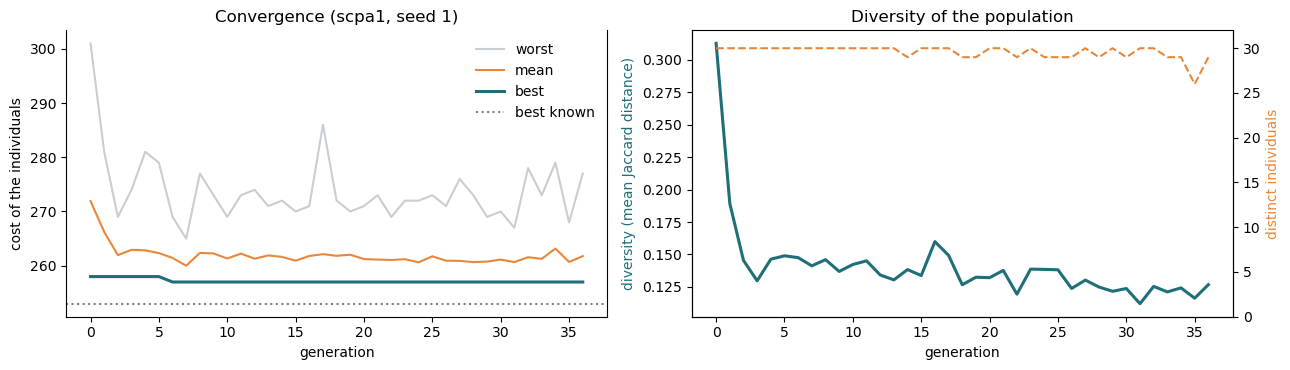

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(h.generation, h.worst, color="#c9ced3", label="worst"); axs[0].plot(h.generation, h["mean"], color="#e8873a", label="mean")
axs[0].plot(h.generation, h.best, color="#1f6f78", lw=2.2, label="best"); axs[0].axhline(BEST[NAME], color="grey", ls=":", label="best known")
axs[0].set_xlabel("generation"); axs[0].set_ylabel("cost of the individuals"); axs[0].set_title(f"Convergence ({NAME}, seed 1)"); axs[0].legend(frameon=False)
ax2 = axs[1]; ax2.plot(h.generation, h.diversity, color="#1f6f78", lw=2.2); ax2.set_xlabel("generation"); ax2.set_ylabel("diversity (mean Jaccard distance)", color="#1f6f78")
ax3 = ax2.twinx(); ax3.plot(h.generation, h.distinct, color="#e8873a", ls="--"); ax3.set_ylabel("distinct individuals", color="#e8873a"); ax3.set_ylim(0, BASELINE["pop_size"] + 2)
ax2.set_title("Diversity of the population")
for ax in (axs[0], ax2): ax.spines[["top"]].set_visible(False)
plt.tight_layout(); plt.show()

### Randomness and seeds
The only sources of randomness are the Python generator `random.Random(seed)` (selection, repair ties, restricted candidate lists, mutation) and a NumPy generator derived from it (crossover splits).
**The same seed reproduces the run exactly; different seeds give different runs** - their spread is what several seeds are needed for in the tuning phase.

In [21]:
again, info2 = genetic_algorithm(inst, random.Random(1), **BASELINE)
print("same seed twice -> identical result:", bool((again["in_sol"] == best["in_sol"]).all()), "| same history:", info2["history"] == info["history"])
rows = []
for seed in range(1, 8):
    b, i = genetic_algorithm(inst, random.Random(seed), **BASELINE)
    rows.append({"seed": seed, "best cost": b["cost"], "deviation %": dev(b["cost"], BEST[NAME]), "generations": i["generations"], "evaluations": i["evals"], "best found in gen.": i["best_gen"]})
seeds_tab = pd.DataFrame(rows).set_index("seed")
display(seeds_tab.round(2)); print(f"mean deviation {seeds_tab['deviation %'].mean():.2f} %,  std {seeds_tab['deviation %'].std():.2f} pp,  best {seeds_tab['deviation %'].min():.2f} %")

same seed twice -> identical result: True | same history: False


,best cost,deviation %,generations,evaluations,best found in gen.
seed,,,,,
1,257.0,1.58,36,1441,6
2,256.0,1.19,37,1513,7
3,258.0,1.98,32,1303,2
4,254.0,0.40,37,1503,7
5,256.0,1.19,38,1486,8
6,257.0,1.58,37,1448,7
7,256.0,1.19,34,1324,4


mean deviation 1.30 %,  std 0.50 pp,  best 0.40 %


## 9. The five questions - answered with the running code

### Question 1: show one individual. What SCP solution does it represent?

In [22]:
rng = random.Random(3)
pop0 = initial_population(inst, rng, 30, 5)
x = pop0[1]
st1 = show_individual(inst, x, "an individual of the initial population (randomised greedy + RE)")
print(f"\nIt represents the cover made of the {int(x.sum())} sets whose bit is 1; the total cost is the sum of their costs ({st1['cost']:.0f}).")

an individual of the initial population (randomised greedy + RE): x = 111011110111110111111001000100101110010010100111011100100000...   (n = 3000 bits, 73 ones)
   selected sets: [0, 1, 2, 4, 5, 6, 7, 9, 10, 11, 12, 13] ...
   uncovered elements: 0 -> FEASIBLE cover   cost = 269   redundant sets: 0

It represents the cover made of the 73 sets whose bit is 1; the total cost is the sum of their costs (269).


### Question 2: can the method generate an infeasible solution? If yes, what happens next?
Yes: **crossover** (the raw children) and **mutation** (right after a set has been dropped). We measure it on 300 crossovers of random pairs of the initial population:
the share of raw children that are not covers, how many elements they leave uncovered, and what the repair and RE do next. Nothing infeasible ever enters the population: **repair, then RE**.

In [23]:
nprng = np.random.default_rng(5); rng = random.Random(5)
diag = []
for _ in range(150):
    a, b = rng.sample(range(len(pop0)), 2)
    crossover(inst, pop0[a], pop0[b], rng, nprng, 1, True, diag=diag)
D = pd.DataFrame(diag)
q2 = pd.DataFrame({
    "raw children that are NOT covers [%]": [100 * (D["uncovered before repair"] > 0).mean()],
    "avg uncovered elements (of those)": [D.loc[D["uncovered before repair"] > 0, "uncovered before repair"].mean()],
    "avg sets in the raw child": [D["sets before repair"].mean()],
    "avg sets after repair": [D["sets after repair"].mean()],
    "avg sets after RE": [D["sets after RE"].mean()],
    "children with a redundant set removed by RE [%]": [100 * (D["sets after RE"] < D["sets after repair"]).mean()],
    "avg cost after repair": [D["cost after repair"].mean()],
    "avg cost after RE": [D["cost after RE"].mean()],
    "raw children that are NOT covers [%], whole GA run of Section 8": [100 * info["infeasible_raw_children"] / (2 * info["recombined"])],
}, index=["crossover (300 children)"])
display(q2.round(2).T)
# mutation: the drop leaves elements uncovered, the repair covers them
st = state_from_vector(inst, pop0[1]); j = int(np.flatnonzero(st["in_sol"])[0])
remove_set(inst, st, j)
print(f"mutation: after dropping set {j} the cover is infeasible ({len(st['uncovered'])} uncovered elements) -> repair + RE ->", end=" ")
greedy_complete(inst, st, random.Random(0), forbid=j); redundancy_elimination(inst, st, random.Random(0))
print("feasible again" if not st["uncovered"] else "STILL INFEASIBLE", f"(cost {st['cost']:.0f})")

,crossover (300 children)
raw children that are NOT covers [%],97.00
avg uncovered elements (of those),6.78
avg sets in the raw child,73.47
avg sets after repair,78.79
avg sets after RE,73.15
children with a redundant set removed by RE [%],98.33
avg cost after repair,293.06
avg cost after RE,270.18
"raw children that are NOT covers [%], whole GA run of Section 8",68.56


mutation: after dropping set 0 the cover is infeasible (3 uncovered elements) -> repair + RE -> feasible again (cost 271)


### Question 3: show how one new individual is created from the current population
Step by step on a real population (generation 0 of the run above): two binary tournaments, the common sets, the raw child, repair, RE, mutation.

In [24]:
rng = random.Random(11); nprng = np.random.default_rng(11)
costs0 = np.array([inst["cost"][x].sum() for x in pop0])
ia, ib = tournament(costs0, rng), tournament(costs0, rng)
xa, xb = pop0[ia], pop0[ib]
common, diff = xa & xb, xa ^ xb
take = nprng.random(inst["n"]) < 0.5
raw = common | (diff & take)
st = state_from_vector(inst, raw)
steps = [("parent a (tournament winner)", int(xa.sum()), costs0[ia], "-"), ("parent b (tournament winner)", int(xb.sum()), costs0[ib], "-"),
         ("sets chosen by BOTH parents (kept)", int(common.sum()), float(inst["cost"][common].sum()), "-"),
         ("sets chosen by one parent only", int(diff.sum()), float(inst["cost"][diff].sum()), "-"),
         ("raw child = common + random half of the others", int(raw.sum()), st["cost"], f"{len(st['uncovered'])} elements uncovered")]
n_unc = len(st["uncovered"]); greedy_complete(inst, st, rng)
steps.append(("after REPAIR (greedy ratio rule)", int(st["in_sol"].sum()), st["cost"], f"{len(st['uncovered'])} uncovered (was {n_unc})"))
n_sets = int(st["in_sol"].sum()); redundancy_elimination(inst, st, rng)
steps.append(("after RE", int(st["in_sol"].sum()), st["cost"], f"{n_sets - int(st['in_sol'].sum())} redundant sets removed"))
mutate(inst, st, rng)
steps.append(("after MUTATION (drop one set, repair, RE)", int(st["in_sol"].sum()), st["cost"], "feasible and minimal"))
check_state(inst, st, minimal=True)
pd.DataFrame(steps, columns=["step", "sets", "cost", "note"]).set_index("step")

,sets,cost,note
step,,,
parent a (tournament winner),76,275.0,-
parent b (tournament winner),71,260.0,-
sets chosen by BOTH parents (kept),55,170.0,-
sets chosen by one parent only,37,195.0,-
raw child = common + random half of the others,75,282.0,7 elements uncovered
after REPAIR (greedy ratio rule),81,299.0,0 uncovered (was 7)
after RE,72,269.0,9 redundant sets removed
"after MUTATION (drop one set, repair, RE)",73,272.0,feasible and minimal


### Question 4: where does diversity come from?
Five sources: the **randomised initial population** (different `rcl`), the **random split** of the non-common sets in crossover, **mutation**, the **low selection pressure** of the binary tournament and the **duplicate control**.
We quantify the first ones: the diversity of the initial population, how different a child is from its parents, and how many mutations/duplicate corrections were needed in the run of Section 8.

In [25]:
nprng = np.random.default_rng(2); rng = random.Random(2)
def jacc(a, b):
    u = np.count_nonzero(a | b)
    return 1.0 - np.count_nonzero(a & b) / u if u else 0.0
d_pop = diversity(pop0, nprng)
d_child_parent, d_parents = [], []
for _ in range(100):
    a, b = rng.sample(range(len(pop0)), 2)
    k1, k2 = crossover(inst, pop0[a], pop0[b], rng, nprng, 1, True)
    d_parents.append(jacc(pop0[a], pop0[b])); d_child_parent += [jacc(k1["in_sol"], pop0[a]), jacc(k1["in_sol"], pop0[b])]
q4 = pd.DataFrame({
    "diversity of the initial population (Jaccard)": [d_pop],
    "distance between two parents": [np.mean(d_parents)],
    "distance child - parent (after repair + RE)": [np.mean(d_child_parent)],
    "random mutations in the run (probability 0.2)": [f"{info['mutated']} of {info['children']} children"],
    "duplicates corrected (mutated) in the run": [f"{info['duplicates_fixed']} of {info['children']} children"],
    "diversity at the start / end of the run": [f"{h.diversity.iloc[0]:.2f} / {h.diversity.iloc[-1]:.2f}"],
}, index=["scpa1, seed 1"]).T
q4

,"scpa1, seed 1"
diversity of the initial population (Jaccard),0.333402
distance between two parents,0.346224
distance child - parent (after repair + RE),0.201786
random mutations in the run (probability 0.2),233 of 1008 children
duplicates corrected (mutated) in the run,278 of 1008 children
diversity at the start / end of the run,0.31 / 0.13


### Question 5: why can the search improve without the population immediately becoming identical?
* The initial population is **diverse** (Jaccard distance about 0.3, 30 distinct individuals) and the **elite** guarantees that the best cover is never lost.
* **Selection pressure is low** (binary tournament): weaker individuals still reproduce, so building blocks of *different* covers are recombined. Crossover keeps what the parents share but mixes what they do not: a child is clearly different from its parents (distance 0.20; the parents are at 0.35 from each other).
* **Duplicate control and mutation** keep the population different: more than a quarter of the children would have been copies of an existing individual and were mutated instead - the population keeps 29-30 distinct individuals.
* **But we must be honest about the limits** (see the curves of Section 8 and the numbers below): the diversity falls fast - from 0.31 to about 0.15 within two generations - and then stays at about 0.13: the population is *concentrated* (about 13 % of the sets differ between two individuals) but not identical.
  The **population as a whole improves** (mean cost 272 -> 262, worst 301 -> 277) while the **best cost improves only a little and early** (258 -> 257 in generation 6; over seven seeds the best was found in generations 2-8), and then 30 generations without improvement follow.
  This is **premature convergence** and the main thing to address in the improved versions (larger population, other stopping rule, restarts, stronger diversification).

In [26]:
print(f"generation 0: best {h.best.iloc[0]:.0f}, mean {h['mean'].iloc[0]:.0f}, diversity {h.diversity.iloc[0]:.2f}, distinct {h.distinct.iloc[0]}")
mid = len(h) // 2
print(f"generation {h.generation.iloc[mid]}: best {h.best.iloc[mid]:.0f}, mean {h['mean'].iloc[mid]:.0f}, diversity {h.diversity.iloc[mid]:.2f}, distinct {h.distinct.iloc[mid]}")
print(f"generation {h.generation.iloc[-1]}: best {h.best.iloc[-1]:.0f}, mean {h['mean'].iloc[-1]:.0f}, diversity {h.diversity.iloc[-1]:.2f}, distinct {h.distinct.iloc[-1]}")
print("improvements of the best cost happened in generations:", [int(g) for g, b0, b1 in zip(h.generation[1:], h.best[:-1], h.best[1:]) if b1 < b0 - 1e-9])

generation 0: best 258, mean 272, diversity 0.31, distinct 30
generation 18: best 257, mean 262, diversity 0.13, distinct 29
generation 36: best 257, mean 262, diversity 0.13, distinct 29
improvements of the best cost happened in generations: [6]


## 10. Why RE? Check of the components (ablation)

Four variants of the baseline on six instances (one per instance set, plus `scp42`) with 5 seeds each; the variants differ in **one** component:
**baseline**; **no RE** (children are repaired but redundant sets are kept; RE is applied only once to the final best solution); **no crossover** (`p_cross = 0`: a population of mutated copies); **no mutation** (`p_mut = 0`).
This is a check of the design, **not** the tuning of part 2: the configuration is the untuned baseline and no statistical test is attempted.

In [27]:
VARIANTS = {"baseline": {}, "no RE": {"re_step": False}, "no crossover": {"p_cross": 0.0}, "no mutation": {"p_mut": 0.0}, "no mutation, no dup. control": {"p_mut": 0.0, "dup_control": False}}
ABL_NAMES = ["scp42", "scp62", "scpa1", "scpb2", "scpc1", "scpd2"]
rows = []
t0 = time.perf_counter()
for name in ABL_NAMES:
    ins = byname[name]
    for vname, kw in VARIANTS.items():
        for seed in range(1, 6):
            rng = random.Random(seed)
            b, i = genetic_algorithm(ins, rng, **{**BASELINE, **kw})
            st = state_from_vector(ins, b["in_sol"]); raw_cost = st["cost"]
            redundancy_elimination(ins, st, rng)                     # final RE (only changes anything for the 'no RE' variant)
            rows.append({"instance": name, "variant": vname, "seed": seed, "dev raw %": dev(raw_cost, BEST[name]), "dev %": dev(st["cost"], BEST[name]),
                         "evaluations": i["evals"], "generations": i["generations"]})
abl = pd.DataFrame(rows)
print(f"{len(abl)} runs in {time.perf_counter() - t0:.0f} s")
order = list(VARIANTS)
summary_abl = abl.groupby("variant").agg(**{"avg dev %": ("dev %", "mean"), "std over runs": ("dev %", "std"), "avg generations": ("generations", "mean"), "avg evaluations": ("evaluations", "mean")}).loc[order]
display(summary_abl.round(3))
display(abl.pivot_table(index="instance", columns="variant", values="dev %", aggfunc="mean")[order].round(2))

150 runs in 53 s


,avg dev %,std over runs,avg generations,avg evaluations
variant,,,,
baseline,1.008,0.913,40.433,1612.467
no RE,4.000,1.879,75.333,2667.200
no crossover,1.374,0.997,51.167,816.867
no mutation,0.999,0.735,43.067,1590.133
"no mutation, no dup. control",1.586,1.107,34.200,889.600


variant,baseline,no RE,no crossover,no mutation,"no mutation, no dup. control"
instance,,,,,
scp42,0.00,2.50,0.62,0.23,1.45
scp62,1.51,5.21,1.51,1.23,2.33
scpa1,1.26,2.77,1.74,1.42,1.58
scpb2,0.00,5.26,0.53,0.00,0.00
scpc1,1.76,4.93,2.03,1.59,2.64
scpd2,1.52,3.33,1.82,1.52,1.52


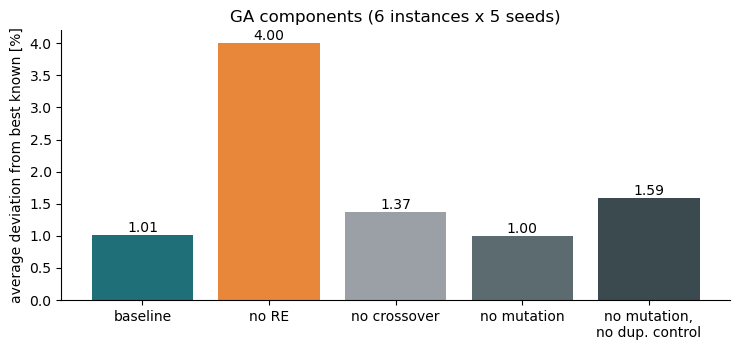

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
vals = summary_abl["avg dev %"]
bars = ax.bar([o.replace(", ", ",\n") for o in order], vals, color=["#1f6f78", "#e8873a", "#9aa0a6", "#5b6b70", "#3b4a4f"])
for r in bars: ax.text(r.get_x() + r.get_width() / 2, r.get_height() + 0.05, f"{r.get_height():.2f}", ha="center")
ax.set_ylabel("average deviation from best known [%]"); ax.set_title("GA components (6 instances x 5 seeds)"); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the ablation** (the variants stop by stagnation, so they use different numbers of evaluations - see the table; this is a check of the design, not a budget-matched comparison).
* **RE is essential:** without it the GA is about **four times worse** (4.0 % vs. 1.0 %) although it runs 65 % more evaluations. The raw children and the sets added by the repair carry redundant, expensive sets; selection then compares covers with noise from redundancy and the population holds non-minimal covers. This justifies RE in every offspring.
* **Crossover pays off:** without it (a population of mutated copies) the result is clearly worse (1.37 % vs. 1.01 %) - recombining the building blocks of two covers is the most productive operator.
* **Diversity maintenance matters, and the random mutation is only one way to provide it:** without random mutation the result is unchanged (1.00 %) - because the **duplicate control still mutates** the children that would be copies (more than a quarter of all children). If **both** are switched off the GA is clearly worse (1.59 %) and converges after fewer evaluations. So the diversification of the population is needed; how much random mutation adds *on top of* the duplicate control is a question for the tuning phase.

## 11. Preliminary results on several instances
The baseline GA on one instance of each set (4, 5, 6, A, B, C, D), 5 seeds, compared with the **start solution CH3 + RE** and - as context only - with the results of the neighbourhood-based metaheuristics of Assignment 3
(tabu search and simulated annealing at a budget of 3000 evaluations, means over 10 seeds from `raw_data_NN3_instance_means.txt`; the GA used about 1700 evaluations on average).

In [29]:
PRE = ["scp42", "scp51", "scp62", "scpa1", "scpb2", "scpc1", "scpd2"]
rows = []
for name in PRE:
    ins = byname[name]
    for seed in range(1, 6):
        rng = random.Random(seed)
        st0 = greedy_individual(ins, random.Random(seed), 1)                        # CH3 + RE with the same seed
        t0 = time.perf_counter()
        b, i = genetic_algorithm(ins, rng, **BASELINE)
        check_state(ins, b, minimal=True)
        rows.append({"instance": name, "seed": seed, "CH3+RE": dev(st0["cost"], BEST[name]), "GA": dev(b["cost"], BEST[name]),
                     "generations": i["generations"], "evaluations": i["evals"], "time s": time.perf_counter() - t0})
pre = pd.DataFrame(rows)
tab = pre.groupby("instance").agg(**{"CH3+RE dev %": ("CH3+RE", "mean"), "GA mean dev %": ("GA", "mean"), "GA best of 5 %": ("GA", "min"), "GA std": ("GA", "std"),
                                       "best known reached": ("GA", lambda v: int((v < 1e-9).sum())), "generations": ("generations", "mean"), "evaluations": ("evaluations", "mean"),
                                       "time s / run": ("time s", "mean")}).loc[PRE]
try:
    ctx = pd.read_csv("raw_data_NN3_instance_means.txt", sep="\t").set_index("instance")
    tab["TS dev % (NN3)"] = ctx.loc[PRE, "TS"]; tab["SA dev % (NN3)"] = ctx.loc[PRE, "SA"]
except Exception as e:                                                                 # the context columns are optional
    print("context from Assignment 3 not available:", e)
avg = tab.mean(numeric_only=True); avg["best known reached"] = tab["best known reached"].sum()
tab.loc["average"] = avg
tab.round(2)

,CH3+RE dev %,GA mean dev %,GA best of 5 %,GA std,best known reached,generations,evaluations,time s / run,TS dev % (NN3),SA dev % (NN3)
instance,,,,,,,,,,
scp42,5.82,0.00,0.00,0.00,5.0,43.60,1800.20,0.26,0.51,2.17
scp51,7.27,1.11,0.40,1.06,0.0,61.80,2453.80,0.40,2.73,2.89
scp62,7.40,1.51,0.00,1.32,1.0,45.00,1807.60,0.26,1.51,2.26
scpa1,6.64,1.26,0.40,0.59,0.0,36.00,1449.20,0.36,1.50,1.78
scpb2,7.89,0.00,0.00,0.00,5.0,32.00,1322.00,0.34,0.79,0.53
scpc1,7.67,1.76,1.76,0.00,0.0,52.80,2036.20,0.57,1.06,1.06
scpd2,3.64,1.52,1.52,0.00,0.0,33.20,1259.60,0.44,0.45,0.76
average,6.62,1.02,0.58,0.42,11.0,43.49,1732.66,0.38,1.22,1.63


## 12. Quality versus effort: the GA against everything before

**Question.** What does the GA give for its effort compared with *all* methods of Assignments 1-3?

**Protocol.** All 42 instances and the seeds 1-10 (the seeds of the final comparison of Assignment 3). Every method is measured from the *empty solution* to its final solution:

| Assignment | Methods | Source of the data |
|---|---|---|
| 1 | constructive heuristics CH1, CH2, CH3, each with and without RE (6) | re-run here |
| 2 | first / best improvement (FI / BI) from CH1, CH2, CH3, CH1+RE and CH3+RE (10) | re-run here |
| 3 | tabu search and simulated annealing, final configurations, budget 3000 evaluations (2) | the raw runs of `NN3.ipynb` (`raw_data_NN3.txt`) |
| 4 | the **baseline GA** (untuned) | run here |

The constructive and local-search methods are re-run in this notebook, so their CPU times come from the **same code and the same machine** as the GA (Assignment 2 used a slower RE, so its old times are not comparable);
as a check, FI and BI from CH3 + RE must reproduce the raw data of Assignment 3 **exactly**. All runs are sequential, so the CPU times (process time, including the construction of the start) are clean.

**Effort** is measured by the CPU time of one run (the main measure) and by the number of evaluated neighbours / individuals. The two differ between methods: the evaluation of a TS / SA neighbour is a *local* change of one cover
(drop a set, repair, RE) whereas the GA builds a whole new cover from two parents (decode the vector, repair, RE), so a GA evaluation costs more CPU time - evaluation counts alone would flatter the GA.
**Caveat:** the stopping rules differ by design (constructive: one pass; local search: first local optimum; TS / SA: fixed budget of 3000 evaluations; GA: stagnation of 30 generations), so this is a comparison of *quality against effort*, not of equal budgets; the GA is untuned.

In [30]:
def local_search(inst, st, rng, pivot):
    # iterative improvement; pivot = "first" (FI) or "best" (BI)
    moves = evals = 0
    trace = [(0, st["cost"])]
    while True:
        st["log"].clear()
        current = st["cost"]
        best_cost, best_ops = current, None
        neighbours = [int(x) for x in selected_sets(st)]
        rng.shuffle(neighbours)
        for j in neighbours:
            mark = len(st["log"])
            apply_move(inst, st, j, rng)
            evals += 1
            if st["cost"] < current - 1e-9:
                if pivot == "first":
                    best_ops = []
                    break
                if st["cost"] < best_cost - 1e-9:
                    best_cost, best_ops = st["cost"], list(st["log"][mark:])
            undo_to(inst, st, mark)
        if best_ops is None:
            break
        if pivot == "best":
            replay_ops(inst, st, best_ops)
        moves += 1
        trace.append((evals, st["cost"]))
    return st, {"evals": evals, "moves": moves, "trace": trace}

In [31]:
def ch2(inst, rng):
    # random uncovered element -> the set covering it with the lowest cost / new_cov (Assignment 1)
    st = new_state(inst)
    while st["uncovered"]:
        e = st["uncovered"][rng.randrange(len(st["uncovered"]))]
        cols = inst["cols_of_row"][e]
        ratio = inst["cost"][cols] / st["new_cov"][cols]
        best = cols[ratio == ratio.min()]
        add_set(inst, st, int(best[rng.randrange(len(best))]))
    return st


def make_start(inst, rng, kind):
    # CH1 / CH2 / CH3, optionally followed by RE ("CH3+RE")
    st = {"CH1": ch1, "CH2": ch2, "CH3": ch3}[kind.replace("+RE", "")](inst, rng)
    if kind.endswith("+RE"):
        redundancy_elimination(inst, st, rng)
    st["log"].clear()
    return st


def cost_at(trace, c):
    # best-so-far cost after c evaluations (the trace lists (evaluations, best cost) after each improvement)
    val = trace[0][1]
    for ev, cost in trace:
        if ev <= c:
            val = cost
        else:
            break
    return val

In [32]:
SEEDS = tuple(range(1, 11))
CHECK = (100, 300, 1000, 3000)
CONSTRUCTIVE_METHODS = ["CH1", "CH2", "CH3", "CH1+RE", "CH2+RE", "CH3+RE"]
LS_METHODS = [f"{k} + {a}" for k in ("CH1", "CH2", "CH3", "CH1+RE", "CH3+RE") for a in ("FI", "BI")]
ga_time_traces = {}                                            # (instance, seed) -> [(cpu time, best cost) per generation]


def run_method(inst, seed, method):
    name, rng = inst["name"], random.Random(seed)
    row = {"method": method, "instance": name, "seed": seed}
    t0 = time.process_time()
    if method == "GA":
        st, info = genetic_algorithm(inst, rng, **BASELINE)
        hist = info["history"]
        for c in CHECK:
            row[f"dev_at_{c}"] = dev(min(x[2] for x in hist if x[1] <= c) if c < info["evals"] else st["cost"], BEST[name])
        ga_time_traces[(name, seed)] = [(x[7], x[2]) for x in hist]
        evals = info["evals"]
    elif " + " in method:                                       # local search from a constructed start
        kind, alg = method.split(" + ")
        st = make_start(inst, rng, kind)
        st, info = local_search(inst, st, rng, "first" if alg == "FI" else "best")
        evals = info["evals"]
        for c in CHECK:
            row[f"dev_at_{c}"] = dev(cost_at(info["trace"], c) if c < evals else st["cost"], BEST[name])
    else:                                                       # constructive heuristic
        st = make_start(inst, rng, method)
        evals = 0
    row.update(cpu_s=time.process_time() - t0, evals=evals, cost=st["cost"], dev=dev(st["cost"], BEST[name]))
    if seed == 1 or method == "GA":                             # verification outside the timing (a sample for the cheap methods)
        check_state(inst, st, complete=True, minimal=(method == "GA" or "+RE" in method.split(" + ")[0]))
    return row


t0 = time.perf_counter()
rows = [run_method(inst, seed, m) for inst in instances for seed in SEEDS for m in CONSTRUCTIVE_METHODS + LS_METHODS + ["GA"]]
mine = pd.DataFrame(rows)
print(f"{len(mine)} runs in {time.perf_counter() - t0:.0f} s")

7140 runs in 388 s


In [33]:
# the raw runs of Assignment 3 (TS and SA) and the consistency check of the re-run (FI / BI from CH3 + RE must be identical)
nn3 = pd.read_csv("raw_data_NN3.txt", sep="\t")
E3 = nn3[nn3.study == "E_final_comparison"].copy()
chk = mine[mine.method.isin(["CH3+RE + FI", "CH3+RE + BI"])].assign(algorithm=lambda d: d.method.str[-2:])
chk = chk.merge(E3[["algorithm", "instance", "seed", "final_cost", "evals"]], on=["algorithm", "instance", "seed"], suffixes=("", "_nn3"))
assert len(chk) == 2 * 42 * 10 and (chk.cost == chk.final_cost).all() and (chk.evals == chk.evals_nn3).all()
print("FI and BI from CH3 + RE reproduce the raw data of Assignment 3 exactly (840 runs: same costs and same evaluation counts)")

a3 = E3[E3.algorithm.isin(["TS", "SA"])].copy()
a3 = pd.DataFrame({"method": a3.algorithm + " (A3)", "instance": a3.instance, "seed": a3.seed, "cpu_s": a3.cpu_init_s + a3.cpu_s, "evals": a3.evals,
                   "cost": a3.final_cost, "dev": a3.dev, **{f"dev_at_{c}": a3[f"dev_at_{c}"] for c in CHECK}})
allres = pd.concat([mine, a3], ignore_index=True)
FAMILY = {**{m: "1 construction" for m in CONSTRUCTIVE_METHODS}, **{m: "2 local search" for m in LS_METHODS}, "TS (A3)": "3 metaheuristic", "SA (A3)": "3 metaheuristic", "GA": "4 population-based"}
allres["family"] = allres.method.map(FAMILY)
print(len(allres), "runs of", allres.method.nunique(), "methods")

FI and BI from CH3 + RE reproduce the raw data of Assignment 3 exactly (840 runs: same costs and same evaluation counts)
7980 runs of 19 methods


In [34]:
g = allres.groupby("method")
inst_mean = allres.pivot_table(index="instance", columns="method", values="dev", aggfunc="mean")
inst_best = allres.pivot_table(index="instance", columns="method", values="dev", aggfunc="min")
qe = pd.DataFrame({
    "family": g.family.first(),
    "avg dev %": inst_mean.mean(),
    "best-of-10 dev %": inst_best.mean(),
    "std over seeds": allres.groupby(["method", "instance"]).dev.std().groupby("method").mean(),
    "best known reached (of 42)": (inst_best < 1e-9).sum(),
    "evaluations / run": g.evals.mean(),
    "CPU ms / run": 1000 * g.cpu_s.mean(),
}).sort_values(["family", "avg dev %"], ascending=[True, False])
qe.round(2)

,family,avg dev %,best-of-10 dev %,std over seeds,best known reached (of 42),evaluations / run,CPU ms / run
method,,,,,,,
CH1,1 construction,2174.94,1867.49,195.70,0,0.00,0.83
CH1+RE,1 construction,1642.02,1352.87,174.17,0,0.00,0.93
CH2,1 construction,18.92,11.80,5.01,0,0.00,0.96
CH2+RE,1 construction,14.50,7.80,4.65,0,0.00,1.01
CH3,1 construction,12.95,10.58,1.63,0,0.00,1.80
CH3+RE,1 construction,6.03,3.91,1.53,1,0.00,1.87
CH1+RE + FI,2 local search,4.11,1.77,1.78,5,288.53,24.81
CH1 + FI,2 local search,4.00,1.66,1.87,9,291.38,24.95
CH2 + FI,2 local search,3.98,1.23,2.04,9,174.50,15.25


efficient frontier (no other method is both faster and better): ['CH1', 'CH1+RE', 'CH2', 'CH2+RE', 'CH3', 'CH3+RE', 'CH3+RE + FI', 'CH3 + FI', 'CH3+RE + BI', 'CH3 + BI', 'SA (A3)', 'TS (A3)', 'GA']


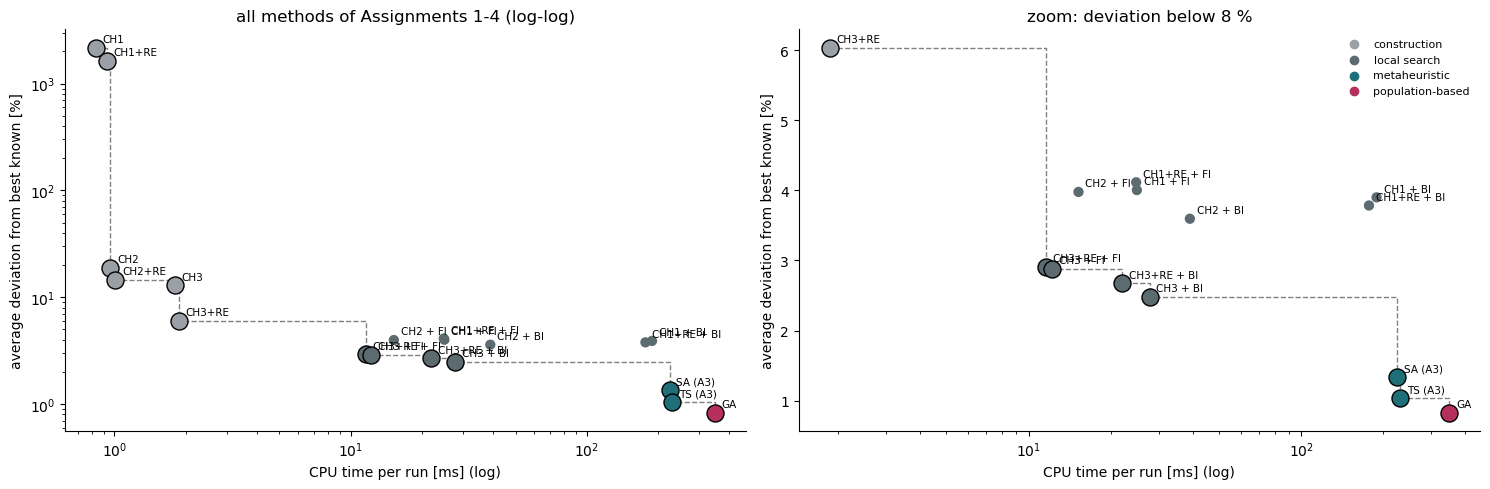

In [35]:
# quality against effort: CPU time per run (log) against the average deviation; the non-dominated methods form the efficient frontier
T, D = qe["CPU ms / run"], qe["avg dev %"]
pareto = [m for m in qe.index if not ((T <= T[m]) & (D <= D[m]) & (T.index != m)).any()]
print("efficient frontier (no other method is both faster and better):", sorted(pareto, key=lambda m: T[m]))
FCOL = {"1 construction": "#9aa0a6", "2 local search": "#5b6b70", "3 metaheuristic": "#1f6f78", "4 population-based": "#b5315b"}
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for ax, zoom in zip(axs, (False, True)):
    for m in qe.index:
        if zoom and D[m] > 8: continue
        ax.scatter(T[m], D[m], s=150 if m in pareto else 55, color=FCOL[qe.family[m]], edgecolor="black" if m in pareto else "none", zorder=3)
        ax.annotate(m, (T[m], D[m]), xytext=(5, 4), textcoords="offset points", fontsize=7.5)
    front = sorted(pareto, key=lambda m: T[m])
    ax.step([T[m] for m in front if (not zoom or D[m] <= 8)], [D[m] for m in front if (not zoom or D[m] <= 8)], where="post", color="grey", ls="--", lw=1, zorder=1)
    ax.set_xscale("log"); ax.set_xlabel("CPU time per run [ms] (log)"); ax.set_ylabel("average deviation from best known [%]")
    ax.spines[["top", "right"]].set_visible(False)
axs[0].set_yscale("log"); axs[0].set_title("all methods of Assignments 1-4 (log-log)"); axs[1].set_title("zoom: deviation below 8 %")
for fam, col in FCOL.items(): axs[1].scatter([], [], color=col, label=fam[2:])
axs[1].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

### Anytime behaviour and equal effort
The search methods (TS, SA, GA) and the local search from CH3 + RE can be compared at **equal numbers of evaluations** (the checkpoints of the best-so-far quality) and at **equal CPU time**
(for TS and SA the time of a checkpoint is the share of their run time, their cost per evaluation is constant; for the GA the time of every generation was recorded).

,after 100 evaluations,after 300 evaluations,after 1000 evaluations,after 3000 evaluations
method,,,,
TS (A3),3.18,2.32,1.49,1.04
SA (A3),3.84,2.67,1.75,1.34
GA,2.54,1.42,0.92,0.83
CH3+RE + FI,3.09,2.91,2.91,2.91
CH3+RE + BI,4.02,2.92,2.67,2.67


,CPU time [ms],TS dev %,SA dev %,GA dev % at this CPU time,GA runs with a solution by then
TS evaluations,,,,,
100,7.66,3.18,3.84,3.28,420 of 420
300,22.99,2.32,2.67,2.23,420 of 420
1000,76.65,1.49,1.75,1.17,420 of 420
3000,229.94,1.04,1.34,0.87,420 of 420


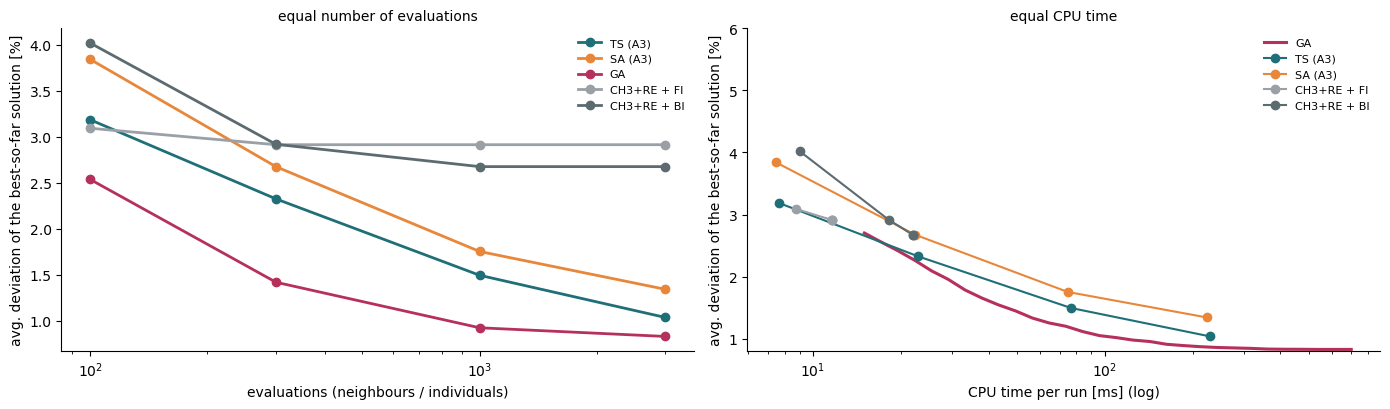

CPU time per evaluation [ms]: {'CH3+RE + BI': 0.089, 'GA': 0.207, 'SA (A3)': 0.075, 'TS (A3)': 0.077}


In [36]:
SEARCH = ["TS (A3)", "SA (A3)", "GA", "CH3+RE + FI", "CH3+RE + BI"]
at = allres[allres.method.isin(SEARCH)].groupby("method")[[f"dev_at_{c}" for c in CHECK]].mean().loc[SEARCH]
at.columns = [f"after {c} evaluations" for c in CHECK]
display(at.round(2))

# equal CPU time: the GA at the time TS needs for 100 / 300 / 1000 / 3000 evaluations
ts = allres[allres.method == "TS (A3)"]
rows = []
for c in CHECK:
    t_c = float((ts.cpu_s * c / ts.evals).mean())                                # mean CPU time of TS after c evaluations
    ga_dev = []
    for (name, seed), tr in ga_time_traces.items():
        ok = [b for t, b in tr if t <= t_c]
        if ok:
            ga_dev.append(dev(min(ok), BEST[name]))
    rows.append({"TS evaluations": c, "CPU time [ms]": 1000 * t_c, "TS dev %": allres[allres.method == "TS (A3)"][f"dev_at_{c}"].mean(),
                 "SA dev %": allres[allres.method == "SA (A3)"][f"dev_at_{c}"].mean(), "GA dev % at this CPU time": np.mean(ga_dev) if ga_dev else np.nan,
                 "GA runs with a solution by then": f"{len(ga_dev)} of {len(ga_time_traces)}"})
eq_time = pd.DataFrame(rows).set_index("TS evaluations")
display(eq_time.round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.2))
COLM = {"TS (A3)": "#1f6f78", "SA (A3)": "#e8873a", "GA": "#b5315b", "CH3+RE + FI": "#9aa0a6", "CH3+RE + BI": "#5b6b70"}
for m in SEARCH:
    axs[0].plot(CHECK, at.loc[m].values, marker="o", lw=2, color=COLM[m], label=m)
axs[0].set_xscale("log"); axs[0].set_xlabel("evaluations (neighbours / individuals)"); axs[0].set_ylabel("avg. deviation of the best-so-far solution [%]"); axs[0].legend(frameon=False, fontsize=8)
axs[0].set_title("equal number of evaluations", fontsize=10)
grid = np.logspace(np.log10(15), np.log10(700), 30)                               # CPU time in ms
ga_curve = []
for t in grid:
    v = [dev(min(b for tt, b in tr if 1000 * tt <= t), BEST[name]) for (name, seed), tr in ga_time_traces.items() if any(1000 * tt <= t for tt, b in tr)]
    ga_curve.append(np.mean(v) if len(v) > 0.5 * len(ga_time_traces) else np.nan)
axs[1].plot(grid, ga_curve, color=COLM["GA"], lw=2.2, label="GA")
for m in SEARCH:
    if m == "GA": continue
    d = allres[allres.method == m]
    xs = [1000 * float((d.cpu_s * np.minimum(c, d.evals) / d.evals).mean()) for c in CHECK]
    axs[1].plot(xs, at.loc[m].values, marker="o", lw=1.5, color=COLM[m], label=m)
axs[1].set_xscale("log"); axs[1].set_xlabel("CPU time per run [ms] (log)"); axs[1].set_ylabel("avg. deviation of the best-so-far solution [%]"); axs[1].set_ylim(0.8, 6)
axs[1].legend(frameon=False, fontsize=8); axs[1].set_title("equal CPU time", fontsize=10)
for ax in axs: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()
per_eval = allres[allres.method.isin(["TS (A3)", "SA (A3)", "GA", "CH3+RE + BI"])].groupby("method").apply(lambda d: 1000 * d.cpu_s.sum() / d.evals.sum(), include_groups=False)
print("CPU time per evaluation [ms]:", per_eval.round(3).to_dict())

In [37]:
# statistical comparison of the five search methods: the instance is the block (deviation averaged over the 10 seeds)
from scipy import stats
from statsmodels.stats.multitest import multipletests
M5 = ["GA", "TS (A3)", "SA (A3)", "CH3+RE + BI", "CH3+RE + FI"]
X = inst_mean[M5]
fr = stats.friedmanchisquare(*[X[m] for m in M5])
print(f"Friedman test over the five methods: chi2 = {fr.statistic:.1f}, p = {fr.pvalue:.3g}; mean ranks:", X.rank(axis=1).mean().round(2).to_dict())
rows = []
for a, b in itertools.combinations(M5, 2):
    w = stats.wilcoxon(X[a], X[b])
    rows.append({"A": a, "B": b, "mean dev A": X[a].mean(), "mean dev B": X[b].mean(), "A better on": int((X[a] < X[b]).sum()), "B better on": int((X[b] < X[a]).sum()), "equal": int((X[a] == X[b]).sum()), "p": w.pvalue})
pw = pd.DataFrame(rows); pw["Holm p"] = multipletests(pw.p, method="holm")[1]
pw.round(4)

Friedman test over the five methods: chi2 = 119.4, p = 7.3e-25; mean ranks: {'GA': 1.7, 'TS (A3)': 1.93, 'SA (A3)': 2.64, 'CH3+RE + BI': 4.06, 'CH3+RE + FI': 4.67}


,A,B,mean dev A,mean dev B,A better on,B better on,equal,p,Holm p
0,GA,TS (A3),0.8274,1.0364,23,15,4,0.0494,0.0494
1,GA,SA (A3),0.8274,1.3422,30,9,3,0.0003,0.0006
2,GA,CH3+RE + BI,0.8274,2.6748,40,1,1,0.0000,0.0000
3,GA,CH3+RE + FI,0.8274,2.9127,41,0,1,0.0000,0.0000
4,TS (A3),SA (A3),1.0364,1.3422,28,7,7,0.0000,0.0000
5,TS (A3),CH3+RE + BI,1.0364,2.6748,39,2,1,0.0000,0.0000
6,TS (A3),CH3+RE + FI,1.0364,2.9127,41,1,0,0.0000,0.0000
7,SA (A3),CH3+RE + BI,1.3422,2.6748,38,3,1,0.0000,0.0000
8,SA (A3),CH3+RE + FI,1.3422,2.9127,39,2,1,0.0000,0.0000
9,CH3+RE + BI,CH3+RE + FI,2.6748,2.9127,29,7,6,0.0002,0.0005


### Reading the comparison
* **Quality ranking (42 instances x 10 seeds, search methods).** GA 0.83 % < TS 1.04 % < SA 1.34 % < BI 2.67 % < FI 2.91 % (local search from CH3 + RE); Friedman test $p=7\cdot10^{-25}$, mean ranks 1.70 / 1.93 / 2.64 / 4.06 / 4.67.
  Every pairwise difference is significant after Holm correction, but **GA vs. TS only marginally** (Holm $p=0.049$; the GA is better on 23 instances, TS on 15, 4 are equal): the GA is clearly better than SA and the local search and *slightly* better than TS. The GA also reaches the best known value on the most instances (26 of 42 in at least one of 10 runs; TS 25, SA 19, BI 8, FI 7) and has the smallest spread over seeds (0.42 pp; TS 0.53, SA 0.55, local search 1.1-1.2).
* **Effort.** The GA is *not* cheap: 348 ms per run against 230 ms (TS), 224 ms (SA), 12-28 ms (local search from CH3) and 1-2 ms (construction). One GA evaluation costs 0.21 ms, 2.7 times a TS / SA evaluation (0.08 ms), because a child is a whole new cover (decode, repair, RE) instead of a local change - so **at an equal number of evaluations the GA looks much better than it is** (after 300 evaluations: GA 1.42 %, TS 2.32 %).
  At an **equal CPU time** the picture is fairer: TS is slightly ahead at about 8 ms (3.18 % vs. 3.28 %), the GA is ahead from about 23 ms on (77 ms: GA 1.17 %, TS 1.49 %, SA 1.75 %; 230 ms: 0.87 % vs. 1.04 % vs. 1.34 %).
* **The efficient frontier** (the labelled big markers) shows the usual staircase: every step down in error costs roughly a factor 10 in time - construction (CH3 + RE: 6.0 % in 2 ms), local search (2.5-2.9 % in 12-28 ms), TS / SA (1.0-1.3 % in about 0.23 s), GA (0.83 % in 0.35 s).
  The metaheuristics cut the error of the local search by more than half for 10-20 times the time; the GA takes a further 20 % off the error of TS for 1.5 times the time (at an equal CPU time, about 16 %). The weaker variants (CH1 / CH2 based local search, CH1) are dominated by CH3-based methods; SA is slightly faster than TS but clearly worse.
* **Caveats.** (1) The methods stop for different reasons (one pass, first local optimum, fixed budget, stagnation), so efforts differ by design. (2) The GA is **untuned** - and about 30 of its roughly 40 generations are the stagnation tail (on `scpa1` the best was found in generations 2-8), so a shorter patience would probably save much of its time; this is a hypothesis for part 2, not a result. (3) The GA's effort includes building 30 initial individuals, TS and SA start from one CH3 + RE solution. (4) TS and SA are the raw runs of Assignment 3 (same seeds, same machine, same building blocks).

## 13. Parameters and baseline for the tuning phase (part 2 - not executed here)

**Parameters that can materially affect the behaviour** and their baseline values (the configuration `BASELINE` above, defined *before* tuning):

| Parameter | Meaning | Baseline | To study |
|---|---|---|---|
| `pop_size` $N$ | individuals per generation; larger = more diversity but fewer generations in the same time | 30 | 10, 20, 30, 50, 100 (**first**, as noted in the discussion) |
| `patience` $\xi$ | generations without improvement before stopping (and the effect of a fixed budget/time instead) | 30 | 10-100; compare under an equal evaluation or time budget |
| `p_cross` $p_c$ | probability that two selected parents are recombined | 0.9 | 0.5-1.0 |
| `p_mut` $p_m$ | probability that a child is mutated (drop-and-repair) | 0.2 | 0, 0.05, 0.1, 0.2, 0.4 |
| `elite` | individuals copied unchanged to the next generation | 2 | 0, 1, 2, 10 % |
| `tour_k` | tournament size = selection pressure (or roulette wheel) | 2 | 2, 3, 5, roulette |
| `rcl_init` | maximum restricted candidate list of the randomised initial individuals (initial diversity and quality) | 5 | 2-10, other mixes (share of CH3 + RE) |
| `rcl_repair` | randomisation of the repair inside crossover and mutation | 1 (greedy) | 1, 2, 3 |
| crossover type | common sets + random split (now) vs. alternatives, e.g. a biased split favouring the cheaper parent | uniform on the differing sets | 2-3 variants |

**Protocol for part 2** (from the assignment): change one parameter or component at a time and record what changed; compare configurations at a **comparable budget** (the same number of evaluations or the same time limit);
use **several seeds** (e.g. 10) and a **tuning subset of instances** with the final check on all 42 (as in Assignment 3); evaluate the quality (average, best, variability), the computation time and the convergence behaviour (best cost per generation and per evaluation, diversity),
and use the paired design with statistical tests of Assignment 3.

## 14. Conclusions of the first iteration

* **Design.** A GA with a **binary-vector representation**, a **corrected crossover** (keep the sets both parents chose, share the others at random, repair with the CH3 rule, RE), the **drop-and-repair mutation**, an initial population from **CH3 + RE and randomised greedy**, **tournament selection**, **elitist generational replacement** with duplicate control and **stagnation-based stopping**.
  Every individual is a feasible, minimal cover; infeasibility appears only transiently (97 % of the raw children of the initial population, about 70 % over a run) and is always repaired.
* **Working version.** It runs from initialisation to termination, the best solution is recovered and verified (from-scratch recomputation **and** an independent re-parse of the instance file), and a seed reproduces a run exactly.
* **Results of the untuned baseline on all 42 instances (10 seeds).** Average deviation **0.83 %** (the start CH3 + RE: 6.03 %), best known value reached on 26 instances, 0.35 s and about 1700 evaluations per run.
  This is better than tabu search (1.04 %), simulated annealing (1.34 %) and the local search (2.7-2.9 %) of Assignments 2-3; the difference to TS is only marginally significant (Holm $p=0.049$), the others are clear.
* **Quality versus effort.** The GA is the most accurate method but not the cheapest (348 ms; TS 230 ms, local search from CH3 12-28 ms): its evaluations cost 2.7 times those of TS / SA, so it looks better at an equal number of evaluations than it is. At an equal CPU time it is ahead of TS from about 23 ms on (e.g. 0.87 % vs. 1.04 % at 230 ms).
* **Components.** RE is essential (about four times worse without it), crossover contributes clearly, and diversity maintenance (random mutation or duplicate control) is needed.
* **Weakness found:** **premature convergence** - the diversity drops from 0.31 to 0.13 within a few generations, the best solution is found early (generations 2-8 on `scpa1`) and the remaining generations bring nothing; this is also where most of the effort is wasted.
* **Open points for part 2:** population size and the stopping rule first (as noted in the discussion) - a shorter patience may remove much of the effort - then the mutation rate and the other parameters of Section 13; the diversification of the population; a comparison with Assignment 3 under a matched budget (equal CPU time) with the same statistical tools.